# Thử nghiệm dự báo độ biến động bằng XGBoost
Notebook này huấn luyện mô hình hồi quy XGBoost dạng bảng với danh sách đặc trưng và thứ tự đã cấu hình trong dự án. Nhãn là độ lệch chuẩn mẫu của lợi suất log hằng ngày trong năm phiên tiếp theo, tính theo điểm phần trăm. Đặc trưng và nhãn được dựng từ tệp OHLCV cục bộ. Các tập huấn luyện và xác thực theo thời gian được dùng để huấn luyện và chọn siêu tham số trong phạm vi giới hạn. Chỉ đánh giá tập kiểm tra sau khi đã chọn tham số.
Chạy notebook từ thư mục gốc của kho mã hoặc từ thư mục `notebooks`.

In [43]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.pipeline.dataset import prepare_dataset, valid_history
from src.evaluation.regression import regression_metrics

config = load_config(ROOT / "config.yaml")
ticker = config["data"].get("ticker", "ACB")
dataset = prepare_dataset(ticker, config)
history = valid_history(dataset)
print(f"Mã cổ phiếu: {ticker} | nhãn: {dataset.target} | kỳ hạn: {dataset.horizon} phiên")
print(f"Train cuối: {dataset.train.date.min().date()} -> {dataset.train.date.max().date()} | số mẫu={len(dataset.train)}")
for i, (_, validation) in enumerate(dataset.validation_folds, start=1):
    print(f"Validation fold {i}: {validation.date.min().date()} -> {validation.date.max().date()} | số mẫu={len(validation)}")
print(f"Test: {dataset.test.date.min().date()} -> {dataset.test.date.max().date()} | số mẫu={len(dataset.test)}")


Mã cổ phiếu: ACB | nhãn: target_volatility_5d | kỳ hạn: 5 phiên
Train cuối: 2018-12-28 -> 2025-08-01 | số mẫu=1639
Validation fold 1: 2023-02-02 -> 2023-07-31 | số mẫu=125
Validation fold 2: 2023-08-01 -> 2024-01-25 | số mẫu=125
Validation fold 3: 2024-01-26 -> 2024-07-31 | số mẫu=125
Validation fold 4: 2024-08-01 -> 2025-02-03 | số mẫu=125
Validation fold 5: 2025-02-04 -> 2025-08-01 | số mẫu=125
Test: 2025-08-11 -> 2026-10-12 | số mẫu=291


## Chọn tham số bằng tập xác thực và huấn luyện mô hình
Mỗi hàm bên dưới chỉ thay đổi một tham số đang khảo sát. Các tham số XGBoost còn lại dùng giá trị mặc định; `random_state=42` và `n_jobs=2` được cố định để kết quả có thể lặp lại và giới hạn tài nguyên (riêng hàm `n_jobs_error` thay đổi `n_jobs`). Mỗi hàm trả về RMSE huấn luyện và RMSE xác thực trung bình qua các phần chia. Xem từng bảng và biểu đồ, sau đó tự ghép các giá trị đã chọn ở ô kế tiếp.


n_estimators


,n_estimators,Lỗi huấn luyện,Lỗi xác thực
0,0,1.497378,0.861004
1,1,0.906287,0.817876
2,2,0.788658,0.772255
3,3,0.707303,0.747652
4,4,0.643237,0.755722
5,5,0.585491,0.750785



max_depth


,max_depth,Lỗi huấn luyện,Lỗi xác thực
0,0,0.000479,0.929878
1,1,0.737205,0.706755
2,2,0.504884,0.706704
3,3,0.302736,0.804676



learning_rate


...

,subsample,Lỗi huấn luyện,Lỗi xác thực
0,0.40,0.087984,0.879329
1,0.45,0.069127,0.934582
2,0.50,0.055582,0.899085
3,0.55,0.050302,0.854286
4,0.60,0.041478,0.873819
5,0.65,0.038752,0.958152



colsample_bytree


,colsample_bytree,Lỗi huấn luyện,Lỗi xác thực
0,0.1,0.303402,0.804238
1,0.2,0.081343,0.746718
2,0.3,0.047938,0.788267
3,0.4,0.044979,0.791363



n_jobs


,n_jobs,Lỗi huấn luyện,Lỗi xác thực
0,1,0.030675,0.849848
1,2,0.030675,0.849848
2,4,0.030675,0.849848
3,8,0.030675,0.849848
4,16,0.030675,0.849848
5,32,0.030675,0.849848
6,42,0.030675,0.849848


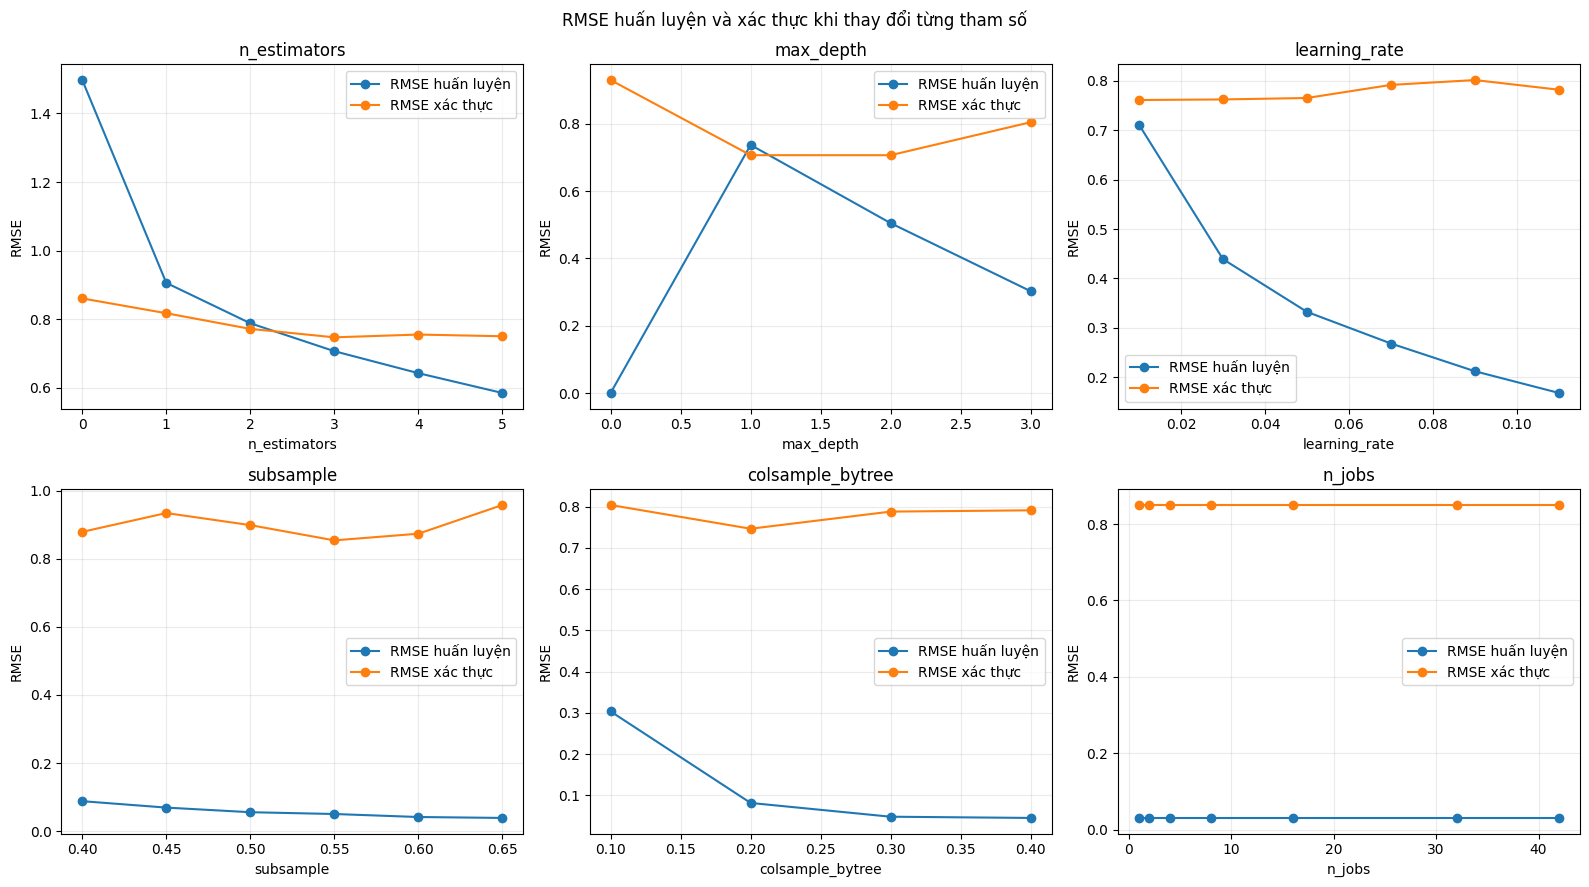

(<Figure size 1600x900 with 6 Axes>,
 array([[<Axes: title={'center': 'n_estimators'}, xlabel='n_estimators', ylabel='RMSE'>,
         <Axes: title={'center': 'max_depth'}, xlabel='max_depth', ylabel='RMSE'>,
         <Axes: title={'center': 'learning_rate'}, xlabel='learning_rate', ylabel='RMSE'>],
        [<Axes: title={'center': 'subsample'}, xlabel='subsample', ylabel='RMSE'>,
         <Axes: title={'center': 'colsample_bytree'}, xlabel='colsample_bytree', ylabel='RMSE'>,
         <Axes: title={'center': 'n_jobs'}, xlabel='n_jobs', ylabel='RMSE'>]],
       dtype=object))

In [44]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from src.pipeline.dataset import feature_matrix
from src.models.xgboost_model import XGBoostModel

base_params = dict(config["models"]["xgboost"])


def _single_parameter_error(parameter_name, value):
    """Thay đổi một tham số XGBoost; giữ các tham số còn lại ở giá trị mặc định."""
    model_params = {parameter_name: value}
    if parameter_name != "n_jobs":
        model_params["n_jobs"] = 2
    train_errors, validation_errors = [], []
    for train, validation in dataset.validation_folds:
        x_train = feature_matrix(train, dataset.features)
        y_train = train[dataset.target].to_numpy(dtype=float)
        x_validation = feature_matrix(validation, dataset.features)
        y_validation = validation[dataset.target].to_numpy(dtype=float)
        model = XGBRegressor(random_state=42, objective="reg:squarederror", **model_params)
        model.fit(x_train, y_train)
        train_prediction = np.maximum(model.predict(x_train), 0)
        validation_prediction = np.maximum(model.predict(x_validation), 0)
        train_errors.append(float(np.sqrt(mean_squared_error(y_train, train_prediction))))
        validation_errors.append(float(np.sqrt(mean_squared_error(y_validation, validation_prediction))))
    return {
        parameter_name: value,
        "Lỗi huấn luyện": float(np.mean(train_errors)),
        "Lỗi xác thực": float(np.mean(validation_errors)),
    }


def n_estimators_error(es):
    return _single_parameter_error("n_estimators", es)


def max_depth_error(depth):
    return _single_parameter_error("max_depth", depth)


def learning_rate_error(rate):
    return _single_parameter_error("learning_rate", rate)


def subsample_error(sample_rate):
    return _single_parameter_error("subsample", sample_rate)


def colsample_bytree_error(column_rate):
    return _single_parameter_error("colsample_bytree", column_rate)


def n_jobs_error(jobs):
    return _single_parameter_error("n_jobs", jobs)


parameter_functions = {
    "n_estimators": (n_estimators_error, np.arange(0,6,1)),
    "max_depth": (max_depth_error, np.arange(0,4,1)),
    "learning_rate": (learning_rate_error, np.arange(0.01,0.12,0.02)),
    "subsample": (subsample_error, np.arange(0.4,0.7,0.05)),
    "colsample_bytree": (colsample_bytree_error, np.arange(0.1,0.4,0.1)),
    "n_jobs": (n_jobs_error, [1,2,4,8,16,32,42]),
}
parameter_results = {
    name: [evaluate(value) for value in values]
    for name, (evaluate, values) in parameter_functions.items()
}
for name, rows in parameter_results.items():
    print(f"\n{name}")
    display(pd.DataFrame(rows))


def plot_parameter_errors(results_by_parameter):
    """Vẽ RMSE huấn luyện và xác thực cho từng lần khảo sát một tham số."""
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for ax, (name, rows) in zip(axes.ravel(), results_by_parameter.items()):
        values = [row[name] for row in rows]
        ax.plot(values, [row["Lỗi huấn luyện"] for row in rows], marker="o", label="RMSE huấn luyện")
        ax.plot(values, [row["Lỗi xác thực"] for row in rows], marker="o", label="RMSE xác thực")
        ax.set_title(name)
        ax.set_xlabel(name)
        ax.set_ylabel("RMSE")
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle("RMSE huấn luyện và xác thực khi thay đổi từng tham số")
    fig.tight_layout()
    plt.show()
    return fig, axes


plot_parameter_errors(parameter_results)


In [45]:
from src.models.xgboost_tuning import tune_xgboost

xgboost_settings = dict(config["models"]["xgboost"])
tuning_config = xgboost_settings.pop("tuning")
tuning_result = tune_xgboost(
    dataset.train,
    dataset.validation_folds,
    dataset.features,
    dataset.target,
    xgboost_settings,
    tuning_config,
    seed=config["seed"],
)
selected_params = {**xgboost_settings, **tuning_result["params"]}

print("Tham số tốt nhất:", tuning_result["params"])
print("RMSE xác thực trung bình:", tuning_result["mean_validation_rmse"])
print("RMSE xác thực gộp:", tuning_result["validation_rmse"])
print("RMSE baseline:", tuning_result["baseline_validation_rmse"])
display(pd.DataFrame({
    "Fold xác thực": range(1, len(tuning_result["fold_validation_rmse"]) + 1),
    "RMSE": tuning_result["fold_validation_rmse"],
}))

Tham số tốt nhất: {'colsample_bytree': 0.3, 'learning_rate': 0.11, 'max_depth': 3, 'n_estimators': 5, 'subsample': 0.55}
RMSE xác thực trung bình: 0.7647706934143115
RMSE xác thực gộp: 0.7895042025874596
RMSE baseline: {'training_target_mean': 0.8611186151550762, 'rolling_volatility_5': 0.7926271425686607}


,Fold xác thực,RMSE
0,1,0.807357
1,2,0.587924
2,3,0.666954
3,4,0.633193
4,5,1.128425


## Fit mô hình cuối

GridSearch đã chọn tham số trên các fold thời gian. Mô hình cuối được fit trên toàn bộ dữ liệu trước tập kiểm tra; tập kiểm tra không tham gia chọn tham số.

In [46]:
model = XGBoostModel(
    dataset.features, dataset.target, dataset.horizon,
    params=selected_params, seed=config["seed"],
).fit(dataset.train)
print("Mô hình cuối đã fit với:", selected_params)

Mô hình cuối đã fit với: {'n_estimators': 5, 'max_depth': 3, 'learning_rate': 0.11, 'subsample': 0.55, 'colsample_bytree': 0.3, 'min_child_weight': 1, 'reg_lambda': 1.0, 'n_jobs': 1}


## Đánh giá trên tập kiểm tra độc lập

Sau khi chọn tham số bằng các fold xác thực, đánh giá mô hình một lần trên giai đoạn kiểm tra chưa dùng trong tuning. Dự báo âm được chặn tại 0 vì độ biến động không âm.

In [47]:
test_forecast = model.predict(history, dataset.test["date"])
actual = dataset.test[["date", dataset.target]].rename(columns={dataset.target: "actual_volatility"})
comparison = actual.merge(test_forecast, on="date", validate="one_to_one")
metrics = regression_metrics(comparison["actual_volatility"], comparison["predicted_volatility"])
print("Các chỉ số test:", metrics)
display(comparison.rename(columns={
    "date": "Ngày",
    "actual_volatility": "Độ biến động thực tế",
    "predicted_volatility": "Độ biến động dự báo",
    "model": "Mô hình",
    "raw_prediction": "Dự báo thô",
}).head())

Các chỉ số test: {'mae': 0.6474096900596978, 'rmse': 0.8798181317307969, 'r2': 0.008645054348041414, 'samples': 291}


,Ngày,Độ biến động thực tế,Mô hình,Độ biến động dự báo,Dự báo thô
0,2025-08-11,2.745265,xgboost,1.507490,1.507490
1,2025-08-12,2.513354,xgboost,1.507490,1.507490
2,2025-08-13,3.251424,xgboost,1.507490,1.507490
3,2025-08-14,2.796236,xgboost,1.760896,1.760896
4,2025-08-15,4.555686,xgboost,1.710133,1.710133


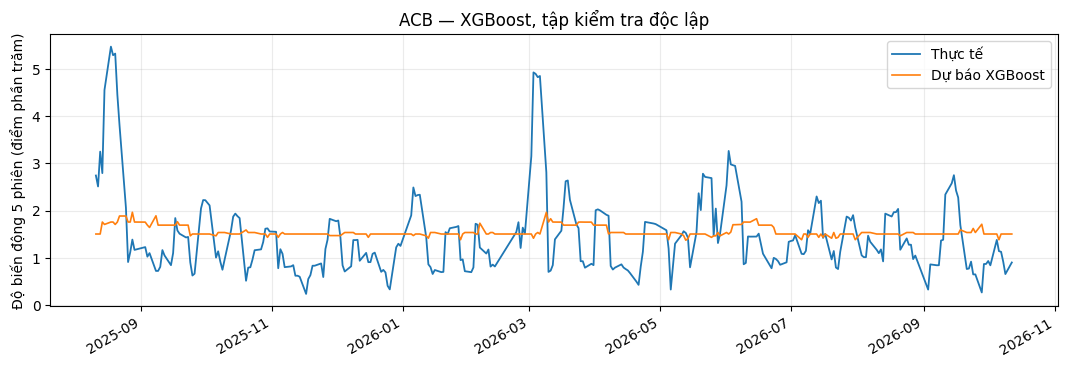

In [48]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(comparison["date"], comparison["actual_volatility"], label="Thực tế", linewidth=1.3)
ax.plot(comparison["date"], comparison["predicted_volatility"], label="Dự báo XGBoost", linewidth=1.2)
ax.set(title=f"{ticker} — XGBoost, tập kiểm tra độc lập",
       ylabel="Độ biến động 5 phiên (điểm phần trăm)")
ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); plt.show()

## Mức độ quan trọng của đặc trưng

Biểu đồ trình bày mức độ quan trọng theo số lần phân tách của mô hình cuối. Đây là thông tin mô tả, không thể hiện quan hệ nhân quả; các đặc trưng trung bình trượt có tương quan với nhau nên mức độ quan trọng có thể thiếu ổn định.

,Mức độ quan trọng
Đặc trưng,
return_1d,0.000000
MA_20,0.000000
volume_change,0.000000
volume_ma_20,0.000000
open_close_range,0.038180
MA_5,0.046723
MA_50,0.049801
rolling_volatility_5,0.062291
MA_10,0.076066


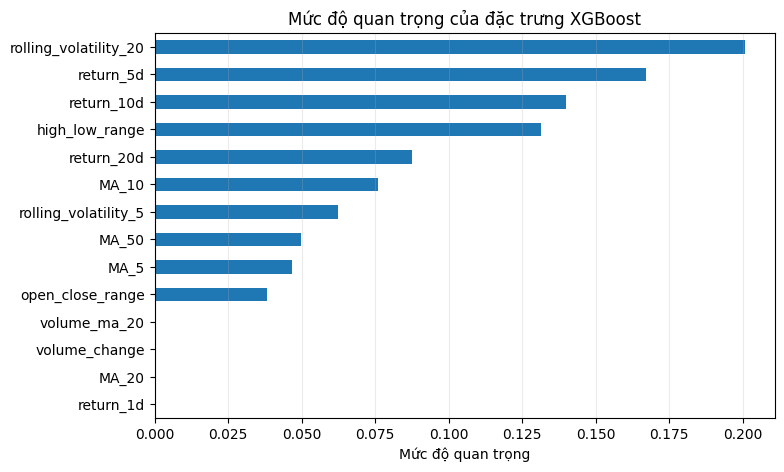

In [49]:
importance = pd.Series(
    model.estimator.feature_importances_, index=dataset.features, name="Mức độ quan trọng"
).sort_values()
display(importance.rename_axis("Đặc trưng").to_frame())
ax = importance.plot.barh(figsize=(8, 5), title="Mức độ quan trọng của đặc trưng XGBoost")
ax.set_xlabel("Mức độ quan trọng"); ax.grid(axis="x", alpha=.25); plt.show()

## Kiểm tra phần dư

Phần dư là dự báo trừ độ biến động thực tế. Các biểu đồ dưới đây mô tả sai số trên tập kiểm tra; không dùng chúng để điều chỉnh tham số sau khi đã xem kết quả test.

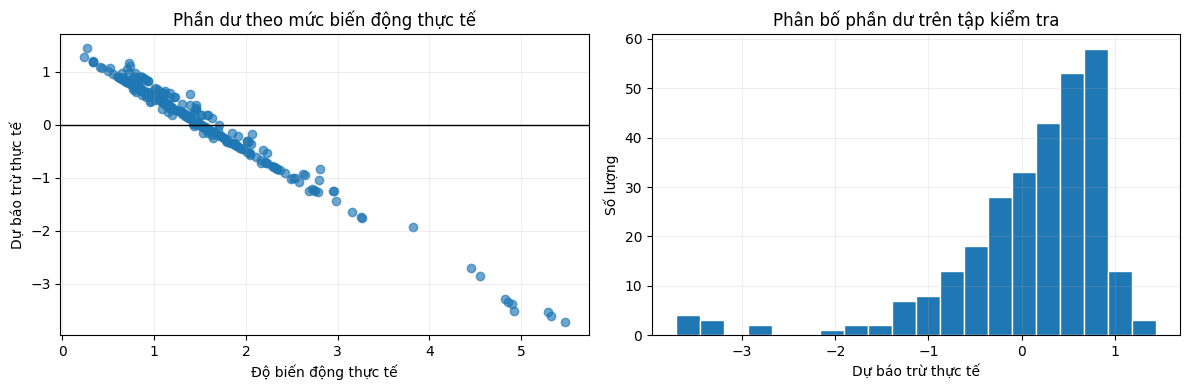

In [50]:
comparison["residual"] = comparison["predicted_volatility"] - comparison["actual_volatility"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(comparison["actual_volatility"], comparison["residual"], alpha=.65)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(xlabel="Độ biến động thực tế", ylabel="Dự báo trừ thực tế",
            title="Phần dư theo mức biến động thực tế")
axes[1].hist(comparison["residual"], bins=20, edgecolor="white")
axes[1].set(xlabel="Dự báo trừ thực tế", ylabel="Số lượng",
            title="Phân bố phần dư trên tập kiểm tra")
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## Tổng kết

- Tham số được chọn bằng GridSearch trên các fold xác thực theo thời gian; baseline được báo cáo để có mốc so sánh.
- Mô hình cuối được fit lại trên dữ liệu trước giai đoạn kiểm tra.
- Chỉ số cuối cùng được tính trên tập kiểm tra độc lập; không dùng kết quả test để quay lại chọn tham số.